In [2]:
# For this notebook to run with updated APIs, we need torch 1.12+ and torchvision 0.13+
# (torch/torchvision are pinned in environment.yml; don't auto-install here)
import torch
import torchvision
from packaging.version import Version

assert Version(torch.__version__.split("+")[0]) >= Version("1.12"), "torch version should be 1.12+"
assert Version(torchvision.__version__.split("+")[0]) >= Version("0.13"), "torchvision version should be 0.13+"
print(f"torch version: {torch.__version__}")
print(f"torchvision version: {torchvision.__version__}")

torch version: 2.11.0+cu128
torchvision version: 0.26.0+cu128


In [3]:
# Continue with regular imports
import matplotlib.pyplot as plt
import torch
import torchvision

from torch import nn
from torchvision import transforms
from torchinfo import summary  # pinned in environment.yml

# Try to import the going_modular directory, download it from GitHub if it doesn't work
try:
    from going_modular.going_modular import data_setup, engine
except ImportError:
    # Sparse, shallow clone of just going_modular/ (the full repo is several GB)
    print("[INFO] Couldn't find going_modular scripts... downloading them from GitHub.")
    !git clone -q --depth 1 --filter=blob:none --sparse https://github.com/mrdbourke/pytorch-deep-learning
    !git -C pytorch-deep-learning sparse-checkout set going_modular
    !mv pytorch-deep-learning/going_modular .
    !rm -rf pytorch-deep-learning
    from going_modular.going_modular import data_setup, engine

In [4]:
# Setup device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    torch.backends.cudnn.benchmark = True # let cuDNN pick the fastest conv algorithms (input size is fixed at 224x224)
device

GPU: NVIDIA GeForce RTX 3090 Ti


'cuda'

In [5]:
import os
import zipfile

from pathlib import Path

import requests

# Setup path to data folder
data_path = Path("data/")
image_path = data_path / "pizza_steak_sushi"

# If the image folder doesn't exist, download it and prepare it...
if image_path.is_dir():
    print(f"{image_path} directory exists.")
else:
    print(f"Did not find {image_path} directory, creating one...")
    image_path.mkdir(parents=True, exist_ok=True)

    # Download pizza, steak, sushi data
    with open(data_path / "pizza_steak_sushi.zip", "wb") as f:
        request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")
        print("Downloading pizza, steak, sushi data...")
        f.write(request.content)

    # Unzip pizza, steak, sushi data
    with zipfile.ZipFile(data_path / "pizza_steak_sushi.zip", "r") as zip_ref:
        print("Unzipping pizza, steak, sushi data...")
        zip_ref.extractall(image_path)

    # Remove .zip file
    os.remove(data_path / "pizza_steak_sushi.zip")

data/pizza_steak_sushi directory exists.


In [6]:
# Setup Dirs
train_dir = image_path / "train"
test_dir = image_path / "test"
# Don't use os.cpu_count() (128 here): forking that many DataLoader workers from a Jupyter kernel
# is very slow and can hang. A few workers are plenty to keep the GPU fed on this small dataset.
NUM_WORKERS = min(4, os.cpu_count())
NUM_WORKERS

4

In [7]:
# Create a transforms pipeline manually (required for torchvision < 0.13)
manual_transforms = transforms.Compose([
    transforms.Resize((224, 224)), # 1. Reshape all images to 224x224 (though some models may require different sizes)
    transforms.ToTensor(), # 2. Turn image values to between 0 & 1
    transforms.Normalize(mean=[0.485, 0.456, 0.406], # 3. A mean of [0.485, 0.456, 0.406] (across each colour channel)
                         std=[0.229, 0.224, 0.225]) # 4. A standard deviation of [0.229, 0.224, 0.225] (across each colour channel),
    # output[c] = (input[c] - mean[c]) / std[c]
    # With your values:
    #
    # R' = (R - 0.485) / 0.229
    # G' = (G - 0.456) / 0.224
    # B' = (B - 0.406) / 0.225
])

In [8]:
# Create training and testing DataLoaders as well as get a list of class names
train_dataloader, test_dataloader, class_names = data_setup.create_dataloaders(train_dir=train_dir,
                                                                               test_dir=test_dir,
                                                                               transform=manual_transforms, # resize, convert images to between 0 & 1 and normalize them
                                                                               batch_size=32, # set mini-batch size to 32
                                                                               num_workers=NUM_WORKERS)

train_dataloader, test_dataloader, class_names

(<torch.utils.data.dataloader.DataLoader at 0x797c386b7a50>,
 ['pizza', 'steak', 'sushi'])

In [9]:
weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT
auto_transforms = weights.transforms()
auto_transforms

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BICUBIC
)

In [10]:
# OLD: Setup the model with pretrained weights and send it to the target device (this was prior to torchvision v0.13)
# model = torchvision.models.efficientnet_b0(pretrained=True).to(device) # OLD method (with pretrained=True)

# NEW: Setup the model with pretrained weights and send it to the target device (torchvision v0.13+)
# Weights are the learned parameters of a model. They are stored in a state_dict, which is a dictionary mapping parameter names to tensors. The state_dict is saved to disk in a .pth file, which can be loaded into a model using the load_state_dict() method.
#They aren't stored in the weights object itself. That object only holds the URL of a file. The parameters are in that file: a .pth file containing a state_dict.

# 1. What the file contains
#
# A state_dict is a plain ordered dictionary from parameter name to tensor. Each layer from the table contributes its own entries:
#
# state_dict = weights.get_state_dict(progress=True)   # downloads (once) and loads the file
#
# for name, tensor in list(state_dict.items())[:8]:
#     print(name, tuple(tensor.shape))
# features.0.0.weight                 (32, 3, 3, 3)    ← Conv2d kernels [out_ch, in_ch, k, k]
# features.0.1.weight                 (32,)            ← BatchNorm γ
# features.0.1.bias                   (32,)            ← BatchNorm β
# features.0.1.running_mean           (32,)            ← BatchNorm saved mean
# features.0.1.running_var            (32,)            ← BatchNorm saved variance
# features.0.1.num_batches_tracked    ()
# ...
# classifier.1.weight                 (1000, 1280)     ← Linear W [out, in]
# classifier.1.bias                   (1000,)          ← Linear b
#
# - Names follow the module hierarchy: features.0.0.weight means model.features[0][0].weight. This is how each tensor finds its layer when loaded.
# - SiLU, ReLU and pooling have no entries because they have no parameters.
# - BatchNorm also saves running_mean and running_var. These are the mean and std in the table's formula. They aren't learned by gradients; they're statistics collected during training and used in model.eval() mode. They're stored as buffers, which go into the state_dict just like parameters.
#
# 2. How it's stored on disk
#
# The file is written with torch.save(state_dict, path). It's a zip archive:
#
# efficientnet_b0_rwightman-7f5810bc.pth   (~20 MB)
# ├── data.pkl     ← pickled dict structure: names, shapes, dtypes, pointers to storage
# ├── data/0       ← raw float32 bytes of tensor 0
# ├── data/1       ← raw float32 bytes of tensor 1
# └── ...
#
# The numbers are stored as raw binary floats (4 bytes each), not text. About 5.3 million parameters × 4 bytes ≈ 20 MB.
#
# After the first download, it's cached here:
#
# ~/.cache/torch/hub/checkpoints/
#
# 3. How it gets into your model
#
# model = torchvision.models.efficientnet_b0(weights=weights)
# # equivalent to:
# model = torchvision.models.efficientnet_b0()          # architecture, random values
# model.load_state_dict(weights.get_state_dict())       # copy tensors in by name
#
# Your own trained models are saved the same way:
#
# torch.save(model.state_dict(), "models/my_model.pth")    # save
# model.load_state_dict(torch.load("models/my_model.pth")) # load into the same architecture
#
# The .pth files in your pytorch/going_modular/models/ folder are exactly this kind of file.
weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT # .DEFAULT = best available weights
model = torchvision.models.efficientnet_b0(weights=weights).to(device)
#model # uncomment to output (it's very long)

In [11]:
# Freeze all base layers in the "features" section of the model (the feature extractor) by setting requires_grad=False
for param in model.features.parameters():
    param.requires_grad = False

In [12]:
# Create training and testing DataLoaders as well as get a list of class names
train_dataloader, test_dataloader, class_names = data_setup.create_dataloaders(train_dir=train_dir,
                                                                               test_dir=test_dir,
                                                                               transform=auto_transforms, # perform same data transforms on our own data as the pretrained model
                                                                               batch_size=32, # set mini-batch size to 32
                                                                               num_workers=NUM_WORKERS)

train_dataloader, test_dataloader, class_names

(<torch.utils.data.dataloader.DataLoader at 0x797c38603150>,
 ['pizza', 'steak', 'sushi'])

In [13]:
# Print a summary using torchinfo (uncomment for actual output)
summary(model=model,
        input_size=(32, 3, 224, 224), # make sure this is "input_size", not "input_shape"
        # col_names=["input_size"], # uncomment for smaller output
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"],
        device=device # run the dummy forward pass on the GPU
)

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [32, 3, 224, 224]    [32, 1000]           --                   Partial
├─Sequential (features)                                      [32, 3, 224, 224]    [32, 1280, 7, 7]     --                   False
│    └─Conv2dNormActivation (0)                              [32, 3, 224, 224]    [32, 32, 112, 112]   --                   False
│    │    └─Conv2d (0)                                       [32, 3, 224, 224]    [32, 32, 112, 112]   (864)                False
│    │    └─BatchNorm2d (1)                                  [32, 32, 112, 112]   [32, 32, 112, 112]   (64)                 False
│    │    └─SiLU (2)                                         [32, 32, 112, 112]   [32, 32, 112, 112]   --                   --
│    └─Sequential (1)                                        [32, 32, 112, 112]   [32, 

In [14]:
# Set the manual seeds
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# Get the length of class_names (one output unit for each class)
output_shape = len(class_names)
print(f"Number of output units (classes): {output_shape}")
# Recreate the classifier layer and seed it to the target device
model.classifier = torch.nn.Sequential(
    torch.nn.Dropout(p=0.2, inplace=True),
    torch.nn.Linear(in_features=1280,
                    out_features=output_shape, # same number of output units as our number of classes
                    bias=True)).to(device)

Number of output units (classes): 3


In [15]:
# # Do a summary *after* freezing the features and changing the output classifier layer (uncomment for actual output)
summary(model,
        input_size=(32, 3, 224, 224), # make sure this is "input_size", not "input_shape" (batch_size, color_channels, height, width)
        verbose=0,
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"],
        device=device # run the dummy forward pass on the GPU
)

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [32, 3, 224, 224]    [32, 3]              --                   Partial
├─Sequential (features)                                      [32, 3, 224, 224]    [32, 1280, 7, 7]     --                   False
│    └─Conv2dNormActivation (0)                              [32, 3, 224, 224]    [32, 32, 112, 112]   --                   False
│    │    └─Conv2d (0)                                       [32, 3, 224, 224]    [32, 32, 112, 112]   (864)                False
│    │    └─BatchNorm2d (1)                                  [32, 32, 112, 112]   [32, 32, 112, 112]   (64)                 False
│    │    └─SiLU (2)                                         [32, 32, 112, 112]   [32, 32, 112, 112]   --                   --
│    └─Sequential (1)                                        [32, 32, 112, 112]   [32, 

In [16]:
# Define loss and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [17]:
# Set the random seeds
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# Start the timer
from timeit import default_timer as timer
start_time = timer()

# Setup training and save the results
results = engine.train(model=model,
                       train_dataloader=train_dataloader,
                       test_dataloader=test_dataloader,
                       optimizer=optimizer,
                       loss_fn=loss_fn,
                       epochs=5,
                       device=device)

# End the timer and print out how long it took
end_time = timer()
print(f"[INFO] Total training time: {end_time-start_time:.3f} seconds")

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.0924 | train_acc: 0.3984 | test_loss: 0.9132 | test_acc: 0.5398
Epoch: 2 | train_loss: 0.8717 | train_acc: 0.7773 | test_loss: 0.7912 | test_acc: 0.8153
Epoch: 3 | train_loss: 0.7648 | train_acc: 0.7930 | test_loss: 0.7463 | test_acc: 0.8561
Epoch: 4 | train_loss: 0.7109 | train_acc: 0.7539 | test_loss: 0.6373 | test_acc: 0.8655
Epoch: 5 | train_loss: 0.6255 | train_acc: 0.7852 | test_loss: 0.6261 | test_acc: 0.8561
[INFO] Total training time: 43.703 seconds


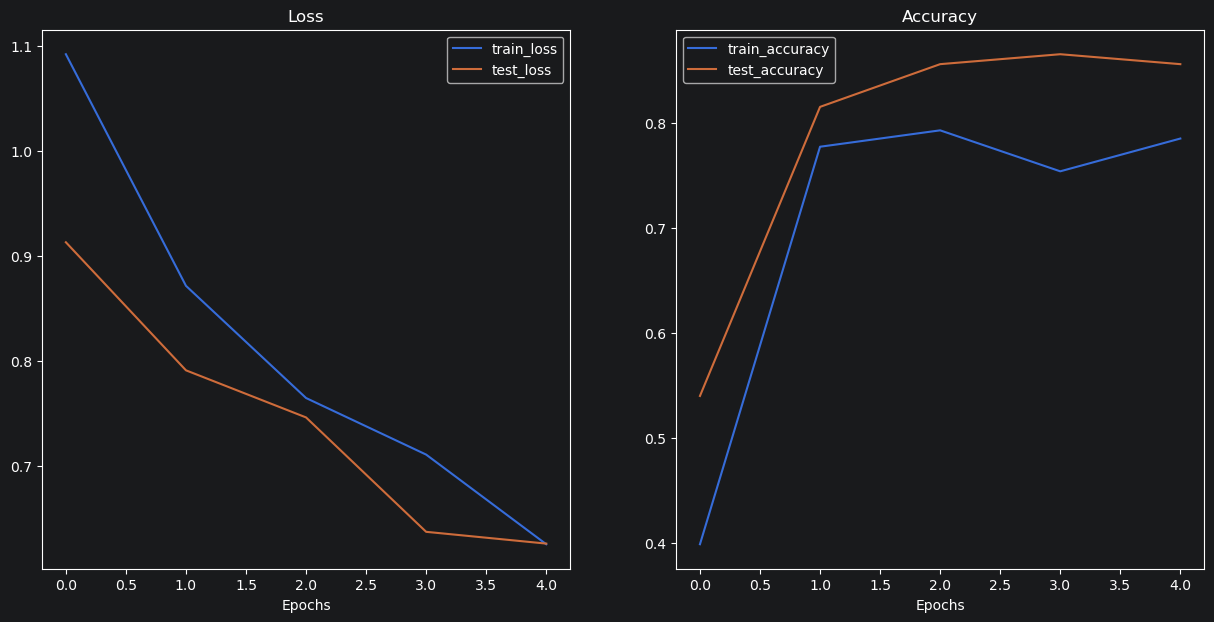

In [18]:
# Get the plot_loss_curves() function from helper_functions.py, download the file if we don't have it
try:
    from helper_functions import plot_loss_curves
except:
    print("[INFO] Couldn't find helper_functions.py, downloading...")
    with open("helper_functions.py", "wb") as f:
        import requests
        request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
        f.write(request.content)
    from helper_functions import plot_loss_curves

# Plot the loss curves of our model
plot_loss_curves(results)

In [19]:
from typing import List, Tuple

from PIL import Image

# 1. Take in a trained model, class names, image path, image size, a transform and target device
def pred_and_plot_image(model: torch.nn.Module,
                        image_path: str,
                        class_names: List[str],
                        image_size: Tuple[int, int] = (224, 224),
                        transform: torchvision.transforms = None,
                        device: torch.device=device):


    # 2. Open image (convert to RGB in case of greyscale/RGBA images)
    img = Image.open(image_path).convert("RGB")

    # 3. Create transformation for image (if one doesn't exist)
    if transform is not None:
        image_transform = transform
    else:
        image_transform = transforms.Compose([
            transforms.Resize(image_size),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                 std=[0.229, 0.224, 0.225]),
        ])

    ### Predict on image ###

    # 4. Make sure the model is on the target device
    model.to(device)

    # 5. Turn on model evaluation mode and inference mode
    model.eval()
    with torch.inference_mode():
      # 6. Transform and add an extra dimension to image (model requires samples in [batch_size, color_channels, height, width])
      transformed_image = image_transform(img)
      transformed_image = transformed_image.unsqueeze(dim=0)
      # 7. Make a prediction on image with an extra dimension and send it to the target device
      target_image_pred = model(transformed_image.to(device))

      # 8. Convert logits -> prediction probabilities (using torch.softmax() for multi-class classification) on the GPU
      target_image_pred_probs = torch.softmax(target_image_pred, dim=1)

      # 9. Convert prediction probabilities -> prediction labels
      target_image_pred_label = torch.argmax(target_image_pred_probs, dim=1)

    # 10. Bring results back to the CPU as Python numbers for plotting
    pred_label = target_image_pred_label.item()
    pred_prob = target_image_pred_probs.max().item()

    # 11. Plot image with predicted label and probability
    plt.figure()
    plt.imshow(img)
    plt.title(f"Pred: {class_names[pred_label]} | Prob: {pred_prob:.3f}")
    plt.axis(False)

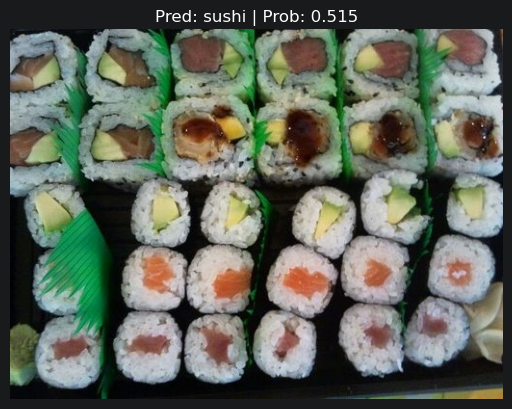

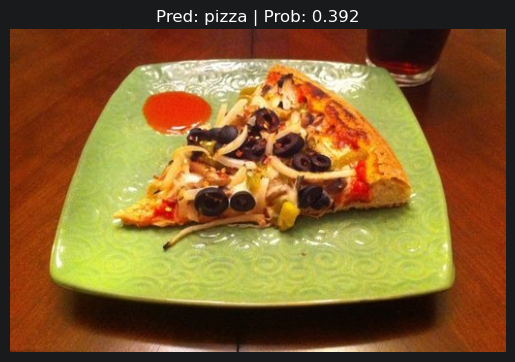

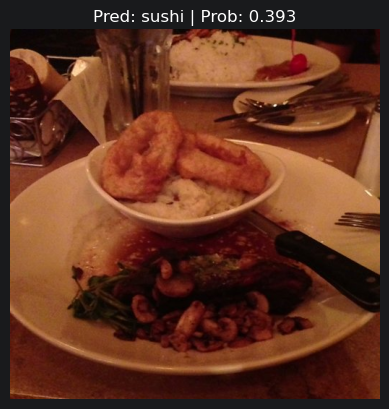

In [20]:
# Get a random list of image paths from test set
import random
num_images_to_plot = 3
test_image_path_list = list(Path(test_dir).glob("*/*.jpg")) # get list all image paths from test data
test_image_path_sample = random.sample(population=test_image_path_list, # go through all of the test image paths
                                       k=num_images_to_plot) # randomly select 'k' image paths to pred and plot

# Make predictions on and plot the images
for image_path in test_image_path_sample:
    pred_and_plot_image(model=model,
                        image_path=image_path,
                        class_names=class_names,
                        # transform=weights.transforms(), # optionally pass in a specified transform from our pretrained model weights
                        image_size=(224, 224))

data/04-pizza-dad.jpeg already exists, skipping download.


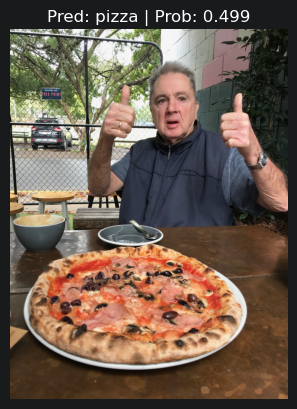

In [21]:
# Download custom image
import requests

# Setup custom image path
custom_image_path = data_path / "04-pizza-dad.jpeg"

# Download the image if it doesn't already exist
if not custom_image_path.is_file():
    with open(custom_image_path, "wb") as f:
        # When downloading from GitHub, need to use the "raw" file link
        request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/04-pizza-dad.jpeg")
        print(f"Downloading {custom_image_path}...")
        f.write(request.content)
else:
    print(f"{custom_image_path} already exists, skipping download.")

# Predict on custom image
pred_and_plot_image(model=model,
                    image_path=custom_image_path,
                    class_names=class_names)

In [25]:
# Import tqdm for progress bar
from tqdm.auto import tqdm

# Make sure the model is on the GPU
model.to(device)

y_preds = []
test_loss, test_acc = 0, 0

model.eval()
with torch.inference_mode():
    for batch, (X, y) in enumerate(tqdm(test_dataloader, desc="Making predictions")):
        # Send data to the GPU (non_blocking works because the DataLoader uses pin_memory=True)
        X, y = X.to(device, non_blocking=True), y.to(device, non_blocking=True)
        y_logits = model(X)

        loss = loss_fn(y_logits, y)
        test_loss += loss.item()

        # Calculate and accumulate accuracy
        pred_labels = torch.softmax(y_logits, dim=1).argmax(dim=1)
        test_acc += ((pred_labels == y).sum().item()/len(pred_labels))

        y_preds.append(pred_labels)

# Concatenate list of per-batch predictions into one tensor (stays on the GPU)
y_preds = torch.cat(y_preds)

# Adjust metrics to get average loss and accuracy per batch
test_loss = test_loss / len(test_dataloader)
test_acc = test_acc / len(test_dataloader)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}")

Making predictions:   0%|          | 0/3 [00:00<?, ?it/s]

Test loss: 0.6261 | Test accuracy: 0.8561


number of classes 3


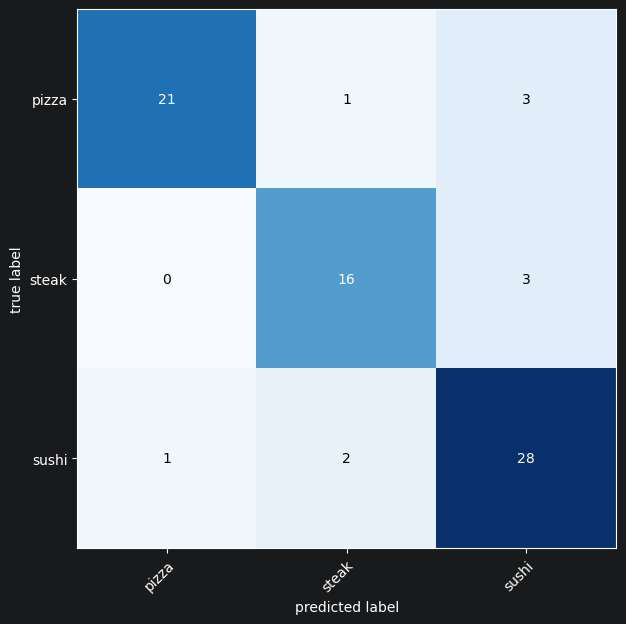

In [23]:

from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix

# 2. Setup confusion matrix instance on the GPU and compare predictions to targets
# (test_dataloader has shuffle=False, so y_preds lines up with dataset.targets)
print('number of classes', len(class_names))
confmat = ConfusionMatrix(num_classes=len(class_names), task='multiclass').to(device)
confmat_tensor = confmat(preds=y_preds,
                         target=torch.tensor(test_dataloader.dataset.targets, device=device)) # targets is a Python list, torchmetrics needs a tensor

# 3. Plot the confusion matrix
fig, ax = plot_confusion_matrix(
    conf_mat=confmat_tensor.cpu().numpy(), # matplotlib likes working with NumPy, which needs the tensor on the CPU
    class_names=class_names, # turn the row and column labels into class names
    figsize=(10, 7)
);
